# Saudi Real Estate Market Analysis

An analysis of recorded real estate sales in Saudi Arabia during Q1 and Q2 2024. The quarterly CSV files are checked, combined, and prepared for the Power BI market overview dashboard.


## Source files

The two quarterly files are loaded separately to check their structure and record counts before combining them.

In [1]:
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)

df_q1 = pd.read_csv("../data/MOJ-Sales-2024-Q1.csv")
df_q2 = pd.read_csv("../data/MOJ-Sales-2024-Q2.csv")

print("Q1:", df_q1.shape)
print("Q2:", df_q2.shape)

Q1: (59099, 10)
Q2: (48272, 10)


## Initial data checks

The first checks cover column names, data types, and missing values in the Q1 and Q2 files.

In [2]:
df_q1.head()

,المنطقة,المدينة,المدينة / الحي,الرقم المرجعي للصفقة,تاريخ الصفقة ميلادي,تاريخ الصفقة هجري,تصنيف العقار,عدد العقارات,السعر,المساحة
0,منطقة مكة المكرمه,الطائف,الطائف/ الجودية,21996239,2024/01/01,1445/06/19,سكني,1,"160,000",555.00
1,منطقة الرياض,الرياض,الرياض/السليمانية,21997463,2024/01/01,1445/06/19,سكني,1,"3,575,000",330.00
2,منطقة الرياض,الرياض,الرياض/السليمانية,21997409,2024/01/01,1445/06/19,سكني,1,"3,575,000",330.00
3,منطقة الرياض,الدلم,الدلم/أخرى,21997190,2024/01/01,1445/06/19,سكني,1,"530,000","5,291.00"
4,منطقة نجران,شروره,شروره/ الوديعة,22000244,2024/01/01,1445/06/19,تجاري,1,"5,000",625.00


In [3]:
df_q1.info()

<class 'pandas.DataFrame'>
RangeIndex: 59099 entries, 0 to 59098
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   المنطقة               59099 non-null  str  
 1   المدينة               59099 non-null  str  
 2   المدينة / الحي        59099 non-null  str  
 3   الرقم المرجعي للصفقة  59099 non-null  int64
 4   تاريخ الصفقة ميلادي   59099 non-null  str  
 5   تاريخ الصفقة هجري     59099 non-null  str  
 6   تصنيف العقار          59099 non-null  str  
 7   عدد العقارات          59099 non-null  int64
 8   السعر                 59099 non-null  str  
 9   المساحة               59099 non-null  str  
dtypes: int64(2), str(8)
memory usage: 4.5 MB


In [4]:
df_q1.isna().sum()

المنطقة                 0
المدينة                 0
المدينة / الحي          0
الرقم المرجعي للصفقة    0
تاريخ الصفقة ميلادي     0
تاريخ الصفقة هجري       0
تصنيف العقار            0
عدد العقارات            0
السعر                   0
المساحة                 0
dtype: int64

In [5]:
df_q2.isna().sum()

المنطقة                 1
المدينة                 1
المدينة / الحي          1
الرقم المرجعي للصفقة    1
تاريخ الصفقة ميلادي     1
تاريخ الصفقة هجري       1
تصنيف العقار            1
عدد العقارات            1
السعر                   1
المساحة                 1
dtype: int64

## Empty records

One completely empty row is removed from Q2. Other records are retained at this stage.

In [6]:
df_q1 = df_q1.dropna(how="all").copy()
df_q2 = df_q2.dropna(how="all").copy()

print("Q1 after cleanup:", len(df_q1))
print("Q2 after cleanup:", len(df_q2))

Q1 after cleanup: 59099
Q2 after cleanup: 48271


## Combining Q1 and Q2

A `quarter` column identifies the source period of each record in the combined dataset.

In [7]:
df_q1["quarter"] = "Q1"
df_q2["quarter"] = "Q2"

df = pd.concat([df_q1, df_q2], ignore_index=True)

df.head()

,المنطقة,المدينة,المدينة / الحي,الرقم المرجعي للصفقة,تاريخ الصفقة ميلادي,تاريخ الصفقة هجري,تصنيف العقار,عدد العقارات,السعر,المساحة,quarter
0,منطقة مكة المكرمه,الطائف,الطائف/ الجودية,"21,996,239.00",2024/01/01,1445/06/19,سكني,1.00,"160,000",555.00,Q1
1,منطقة الرياض,الرياض,الرياض/السليمانية,"21,997,463.00",2024/01/01,1445/06/19,سكني,1.00,"3,575,000",330.00,Q1
2,منطقة الرياض,الرياض,الرياض/السليمانية,"21,997,409.00",2024/01/01,1445/06/19,سكني,1.00,"3,575,000",330.00,Q1
3,منطقة الرياض,الدلم,الدلم/أخرى,"21,997,190.00",2024/01/01,1445/06/19,سكني,1.00,"530,000","5,291.00",Q1
4,منطقة نجران,شروره,شروره/ الوديعة,"22,000,244.00",2024/01/01,1445/06/19,تجاري,1.00,"5,000",625.00,Q1


## Price and area

Price and area are converted to numeric columns so totals, averages, and comparisons can be calculated.

In [8]:
df["السعر"] = pd.to_numeric(df["السعر"].astype(str).str.replace(",", "", regex=False),errors="coerce")

df["المساحة"] = pd.to_numeric(df["المساحة"].astype(str).str.replace(",", "", regex=False),errors="coerce")

df[["السعر", "المساحة"]].describe()

,السعر,المساحة
count,"107,370.00","107,370.00"
mean,"1,193,266.97","4,103.90"
std,"9,164,376.06","72,596.44"
min,"5,000.00",0.52
25%,"200,000.00",300.00
50%,"478,705.00",487.66
75%,"914,000.00",700.00
max,"1,628,410,300.00","8,306,553.02"


## Invalid values

Missing, zero, and negative values are checked before using price and area in the analysis.

In [9]:
print("Missing values:\n")
print(df[["السعر", "المساحة"]].isna().sum())

print("Prices at or below zero:", (df["السعر"] <= 0).sum())
print("Areas at or below zero:", (df["المساحة"] <= 0).sum())

Missing values:

السعر      0
المساحة    0
dtype: int64
Prices at or below zero: 0
Areas at or below zero: 0


## Records used in the analysis

Records with missing or non-positive price or area are excluded from the cleaned table.

In [10]:
df_clean = df.dropna(subset=["السعر", "المساحة"]).copy()

df_clean = df_clean[(df_clean["السعر"] > 0) & (df_clean["المساحة"] > 0)].copy()

print("Before:", len(df))
print("After:", len(df_clean))

Before: 107370
After: 107370


## Transaction references

Repeated transaction reference numbers are checked as part of the data quality review.

In [11]:
print("Repeated transaction references:", df_clean["الرقم المرجعي للصفقة"].duplicated().sum())

Repeated transaction references: 0


## Quarterly comparison

Transaction counts, total recorded values, means, and medians are compared between Q1 and Q2.

In [12]:
quarter_summary = df_clean.groupby("quarter")["السعر"].agg(["count", "sum", "mean", "median"])

quarter_summary

,count,sum,mean,median
quarter,,,,
Q1,59099,70626436002,"1,195,052.98","453,750.00"
Q2,48271,57494638970,"1,191,080.34","500,000.00"


## Regional activity

The number of recorded sales is compared across regions and quarters.

In [13]:
region_counts = pd.crosstab(df_clean["المنطقة"],df_clean["quarter"])

region_counts.sort_values("Q1", ascending=False)

quarter,Q1,Q2
المنطقة,,
منطقة الرياض,24431,18630
منطقة مكة المكرمه,10913,9364
منطقة الشرقية,9131,7524
منطقة القصيم,3760,3058
منطقة حائل,2346,1943
منطقة المدينة المنوره,2323,2205
منطقة عسير,2077,1981
منطقة تبوك,954,741
منطقة جازان,905,985


## Value by region

Total transaction values are grouped by region and quarter to compare the distribution of recorded sales value.

In [14]:
region_values = df_clean.groupby(["المنطقة", "quarter"])["السعر"].sum()

region_values.unstack(fill_value=0)

quarter,Q1,Q2
المنطقة,,
منطقة الباحة,38905222,48508911
منطقة الجوف,101444770,107350265
منطقة الحدود الشمالية,66572547,61828756
منطقة الرياض,36303573813,30478758075
منطقة الشرقية,8550734581,8810996393
منطقة القصيم,1258051387,1058277761
منطقة المدينة المنوره,1825891684,1631585980
منطقة تبوك,480291648,478237515
منطقة جازان,369613357,356176302


## City-level activity

Records are grouped by region and city to avoid combining cities that share a name.

In [15]:
city_counts = df_clean.groupby(["المنطقة", "المدينة", "quarter"]).size()

city_counts.unstack(fill_value=0).sort_values("Q1", ascending=False).head(20)

quarter                                   Q1     Q2
المنطقة               المدينة                      
منطقة الرياض          الرياض           19033  14032
منطقة مكة المكرمه     جده               7029   6340
منطقة الشرقية         الدمام            2450   1656
                      الهفوف            2320   2048
منطقة القصيم          بريده             1990   1690
منطقة مكة المكرمه     مكة المكرمة       1953   1621
منطقة المدينة المنوره المدينة المنورة   1934   1819
منطقة حائل            حائل              1598   1274
منطقة الشرقية         الخبر             1222   1183
منطقة مكة المكرمه     الطائف             891    626
منطقة الشرقية         الجبيل             832    773
منطقة تبوك            تبوك               820    623
منطقة الرياض          الخرج              819    857
منطقة الشرقية         حفر الباطن         817    603
منطقة عسير            خميس مشيط          730    650
منطقة الرياض          الدوادمي           573    413
                      المزاحميه          518    396
منطقة الحدود الشمالية عرعر               510    399
منطقة نجران           نجران              507    373
منطقة عسير            ابها               504    496

## Property classifications

Transaction count, mean, and median are compared for residential, commercial, and agricultural records.

In [16]:
property_summary = df_clean.groupby(["تصنيف العقار", "quarter"])["السعر"].agg(["count", "mean", "median"])

property_summary

count         mean     median
تصنيف العقار quarter                               
تجاري        Q1        7116 3,587,889.95 800,000.00
             Q2        4605 4,198,836.68 950,000.00
زراعي        Q1        1571 1,689,171.01 500,000.00
             Q2        1632 1,445,378.34 600,000.00
سكني         Q1       50412   841,889.30 435,000.00
             Q2       42034   851,694.78 470,000.00

## High-value transactions

The five largest recorded transactions are reviewed because unusually large values can affect the mean.

In [17]:
df_clean.nlargest(5, "السعر")[["quarter", "المنطقة", "المدينة", "تصنيف العقار", "السعر", "المساحة"]]

,quarter,المنطقة,المدينة,تصنيف العقار,السعر,المساحة
92028,Q2,منطقة الرياض,الرياض,تجاري,1628410300,"871,530.00"
19796,Q1,منطقة الرياض,الرياض,تجاري,677445000,"39,850.00"
86575,Q2,منطقة الرياض,الرياض,تجاري,648500000,"127,038.08"
99626,Q2,منطقة مكة المكرمه,جده,سكني,600000000,"3,620,200.00"
46117,Q1,منطقة مكة المكرمه,مكة المكرمة,تجاري,535169556,"4,916.96"


## Transactions by region: Q1 vs Q2

The chart provides a quick comparison of recorded transaction activity across regions.

<Axes: title={'center': 'Real Estate Records: Q1 vs Q2'}, xlabel='المنطقة'>

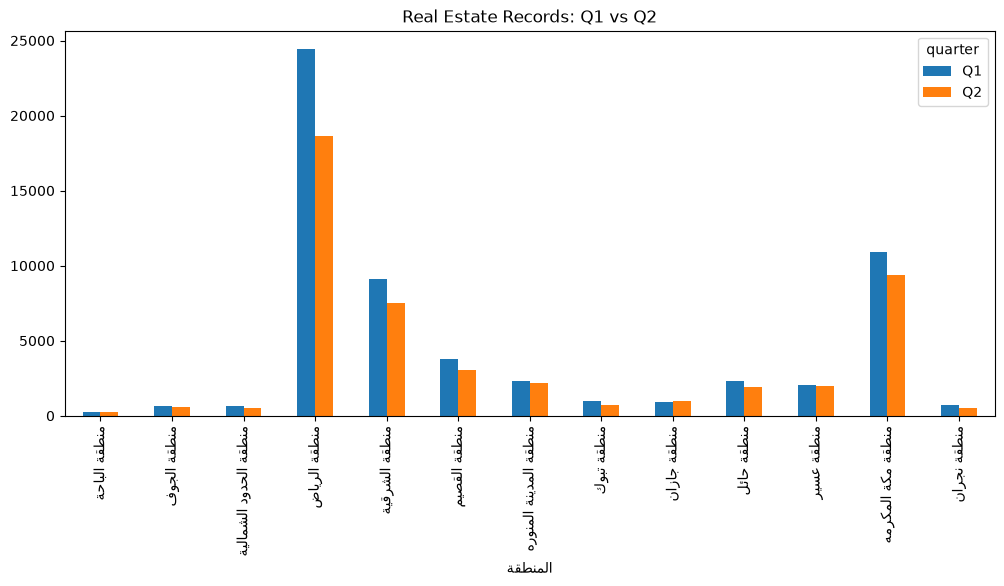

In [18]:
region_counts.plot(kind="bar", figsize=(12, 5), title="Real Estate Records: Q1 vs Q2")

## Power BI dataset

Region labels and Gregorian date formatting are standardized before exporting `real_estate_clean.csv` for the dashboard and prediction notebook.

In [19]:
df_clean["المنطقة"] = df_clean["المنطقة"].str.replace("منطقة ", "", regex=False)

dates = pd.to_datetime(df_clean["تاريخ الصفقة ميلادي"], format="%Y/%m/%d")
df_clean["تاريخ الصفقة ميلادي"] = (
    dates.dt.month.astype(str) + "/" + dates.dt.day.astype(str) + "/" + dates.dt.year.astype(str)
)

df_clean.to_csv("../data/real_estate_clean.csv", index=False, encoding="utf-8-sig", float_format="%.15g")
print("Saved data")

Saved data


## Key findings

- **Q1:** 59,099 records and approximately **SAR 70.63B** in total transaction value.
- **Q2:** 48,271 records and approximately **SAR 57.49B** in total transaction value.
- The number of records declined by **18.3%**, while total transaction value declined by **18.6%**.
- Median transaction value increased from **SAR 453,750** to **SAR 500,000**. Mean value was around **SAR 1.19M** in both quarters.
